# Burgers: PINN base frente a PCA como preprocesamiento

**Pregunta.** En esta primera prueba, ¿qué ocurre con el error de solución, el residuo físico y el tiempo cuando comprimimos los perfiles espaciales con PCA antes de entrenar la red?

La corrida es piloto: tres semillas, un mismo conjunto de minibatches por pareja y `k=4`. La comparación no reemplaza el estudio de tiempo a precisión objetivo.

## Protocolo

- Dominio y datos: `burgers_shock.mat`.
- Semillas: 2026, 2027 y 2028; para cada semilla ambos métodos comparten la partición temporal, los minibatches y los puntos de condición inicial.
- PCA se ajusta solo con los snapshots de entrenamiento. La red predice coeficientes temporales y la reconstrucción espacial usa cuatro modos.
- Tamaño aproximado comparable: 8,577 parámetros para la base y 8,446 para PCA.
- Precisión numérica: float32 en ambos modelos. Métricas de prueba: RMSE, error relativo L2 y RMS del residuo de Burgers calculado en la malla con el mismo operador para ambos modelos. Tiempo de PCA incluye ajuste de base y entrenamiento; compilación JAX se reporta por separado.
- Durante el entrenamiento, la base usa autodiferenciación del MLP; PCA usa derivadas espaciales discretas de los modos y autodiferenciación temporal de los coeficientes. El tiempo reportado compara los pipelines completos, incluyendo esa diferencia de operador.

In [1]:
from pathlib import Path
import json
import sys

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import jax
import numpy as np
import pandas as pd
from IPython.display import SVG, display
from pinn_pca.data import load_burgers_data

CONFIG_PATH = ROOT / "configs" / "burgers_base_vs_pca.json"
CONFIG = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
x, t, u = load_burgers_data(ROOT / CONFIG["data_path"])
print(f"JAX {jax.__version__} | dispositivo: {jax.devices()[0]}")
print(f"Datos: {x.size} puntos espaciales × {t.size} tiempos; u.shape={u.shape}")
print(f"Semillas={CONFIG['seeds']}; pasos={CONFIG['steps']}; k={CONFIG['pca_components']}")

JAX 0.12.0.1 | dispositivo: CpuDevice(id=0)
Datos: 256 puntos espaciales × 100 tiempos; u.shape=(256, 100)
Semillas=[2026, 2027, 2028]; pasos=1000; k=4


In [2]:
from pinn_pca.experiment import run_comparison

run = run_comparison(CONFIG, ROOT)
RESULTS_DIR = run["output_dir"]
print(f"\nResultados guardados en: {RESULTS_DIR.relative_to(ROOT)}")

Seed 2026: training PINN base and PCA(k=4) on shared batches
  Base: test relL2=0.40984, PDE=0.23091, train=2.16s
  PCA:  test relL2=0.30122, PDE=0.22781, pipeline=0.81s, variance=99.967480%
Seed 2027: training PINN base and PCA(k=4) on shared batches
  Base: test relL2=0.4075, PDE=0.22714, train=2.15s
  PCA:  test relL2=0.29042, PDE=0.23215, pipeline=0.83s, variance=99.967372%
Seed 2028: training PINN base and PCA(k=4) on shared batches
  Base: test relL2=0.42929, PDE=0.27562, train=2.16s
  PCA:  test relL2=0.32281, PDE=0.24146, pipeline=0.83s, variance=99.976820%

Resultados guardados en: results/burgers/base_vs_pca/pilot_3_seeds_v1


## Resultados: media ± desviación estándar

El tiempo de compilación inicial se deja aparte del pipeline por corrida. El pipeline de PCA sí incluye el ajuste de la base.

In [3]:
summary_doc = json.loads((RESULTS_DIR / "summary.json").read_text(encoding="utf-8"))
summary = summary_doc["summary"]
compile_seconds = summary_doc["one_time_compilation_seconds"]
rows = []
for method, values in summary.items():
    retained = values["retained_variance_mean"]
    rows.append({
        "Método": method,
        "Parámetros": values["parameters"],
        "k": values["k"] if values["k"] is not None else "—",
        "Varianza retenida": "—" if retained is None else f"{100*retained:.4f}%",
        "RMSE prueba": f"{values['test_rmse']['mean']:.4f} ± {values['test_rmse']['std']:.4f}",
        "Rel. L2 prueba": f"{values['test_relative_l2']['mean']:.4f} ± {values['test_relative_l2']['std']:.4f}",
        "Residuo PDE": f"{values['test_pde_residual_rms']['mean']:.4f} ± {values['test_pde_residual_rms']['std']:.4f}",
        "Pipeline (s)": f"{values['pipeline_seconds']['mean']:.3f} ± {values['pipeline_seconds']['std']:.3f}",
        "Compilación única (s)": f"{compile_seconds[method]:.3f}",
    })
display(pd.DataFrame(rows))

Método,Parámetros,k,Varianza retenida,RMSE prueba,Rel. L2 prueba,Residuo PDE prueba,Pipeline,Compilación única
PINN base,"8,577",—,—,0.2547 ± 0.0141,0.4155 ± 0.0120,0.2446 ± 0.0270,2.156 ± 0.008 s,0.430 s
PCA (k=4),"8,446",4,99.9706%,0.1869 ± 0.0152,0.3048 ± 0.0165,0.2338 ± 0.0070,0.823 ± 0.011 s,0.351 s


## Diferencias pareadas por semilla

Un valor negativo significa que PCA obtuvo un valor menor que la red base para esa métrica. Con tres semillas, estos resultados son descriptivos; el siguiente estudio debe aumentar el número de semillas y comparar tiempo a precisión objetivo.

In [4]:
paired = json.loads((RESULTS_DIR / "summary.json").read_text(encoding="utf-8"))["paired_differences_PCA_minus_base"]
paired_rows = []
for key, label in [("test_relative_l2", "Error relativo L2"),
                   ("test_pde_residual_rms", "Residuo RMS"),
                   ("pipeline_seconds", "Tiempo pipeline")]:
    value = paired[key]
    paired_rows.append({"Métrica": label,
                        "Diferencia media PCA − base": value["PCA_minus_base_mean"],
                        "Semillas donde PCA fue menor": f"{value['PCA_better_count']}/{value['n']}"})
display(pd.DataFrame(paired_rows))

Métrica,Diferencia media PCA − base,PCA menor
Error relativo L2,-0.11073,3/3
Residuo RMS,-0.01075,2/3
Tiempo pipeline,-1.3332,3/3


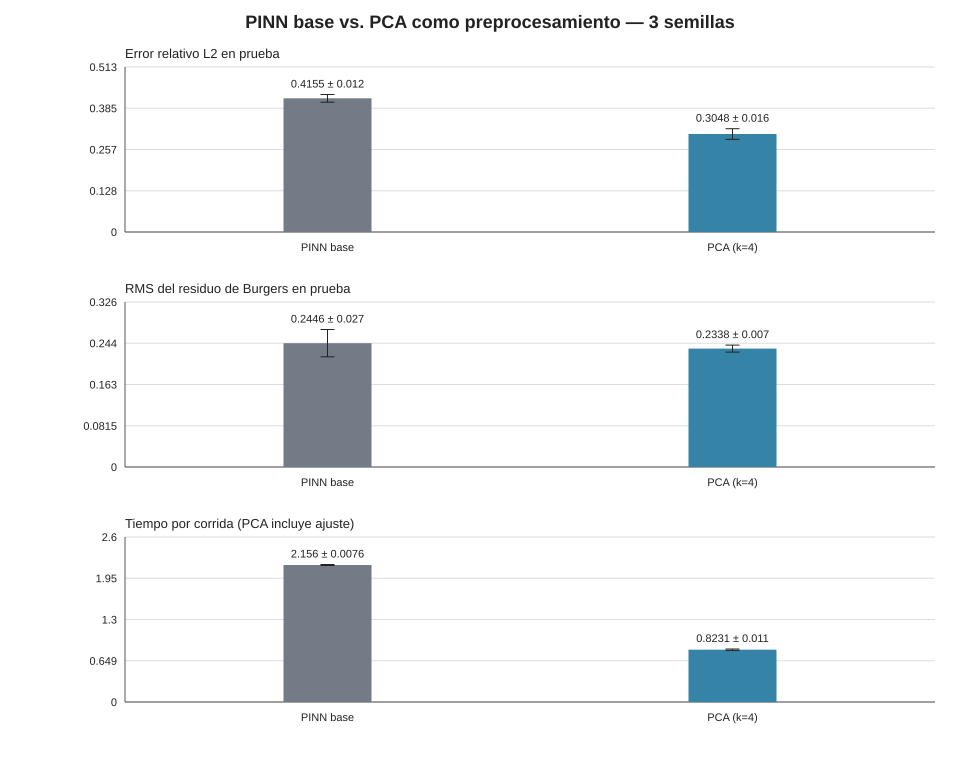

In [5]:
display(SVG(filename=str(RESULTS_DIR / "comparison.svg")))

## Lectura provisional

En este piloto PCA k=4 tuvo menor error relativo L2 en las tres semillas y menor tiempo de pipeline; el residuo RMS fue algo menor en promedio, aunque PCA lo redujo en solo dos de las tres parejas. La proyección retuvo cerca de 99.97% de la varianza.

Esto sirve como verificación inicial de la estructura del experimento, no como conclusión general: faltan más semillas, la comparación a tiempo fijo aún no mide tiempo para alcanzar una precisión dada y se debe repetir en otros tipos de PDE.